In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"khanchughtai","key":"1a1fa7d3d33620d582092f59a094246d"}'}

In [ ]:
import os

# Create Kaggle folder
os.makedirs('/root/.kaggle', exist_ok=True)

# Move kaggle.json to proper location
!mv kaggle.json /root/.kaggle/

# Set permissions
!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d fusicfenta/chest-xray-for-covid19-detection

Dataset URL: https://www.kaggle.com/datasets/fusicfenta/chest-xray-for-covid19-detection
License(s): DbCL-1.0
100% 176M/176M [00:01<00:00, 102MB/s]



In [ ]:
import zipfile

with zipfile.ZipFile('chest-xray-for-covid19-detection.zip', 'r') as zip_ref:
    zip_ref.extractall('dataset')

In [ ]:
import os

dataset_path = 'dataset'

for root, dirs, files in os.walk(dataset_path):
    print(f"Folder: {root}")
    print(f"Subfolders: {dirs}")
    print(f"Files: {len(files)}")
    print('-'*40)

Folder: dataset
Subfolders: ['Dataset']
Files: 0
----------------------------------------
Folder: dataset/Dataset
Subfolders: ['Val', 'Prediction', 'Train']
Files: 0
----------------------------------------
Folder: dataset/Dataset/Val
Subfolders: ['Covid', 'Normal']
Files: 0
----------------------------------------
Folder: dataset/Dataset/Val/Covid
Subfolders: []
Files: 30
----------------------------------------
Folder: dataset/Dataset/Val/Normal
Subfolders: []
Files: 30
----------------------------------------
Folder: dataset/Dataset/Prediction
Subfolders: []
Files: 23
----------------------------------------
Folder: dataset/Dataset/Train
Subfolders: ['Covid', 'Normal']
Files: 0
----------------------------------------
Folder: dataset/Dataset/Train/Covid
Subfolders: []
Files: 144
----------------------------------------
Folder: dataset/Dataset/Train/Normal
Subfolders: []
Files: 144
----------------------------------------


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Rescaling and Data Augmentation for training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True,
    width_shift_range=0.2,
    height_shift_range=0.2
)

# Rescaling only for validation
val_datagen = ImageDataGenerator(rescale=1./255)

# Train generator
train_data = train_datagen.flow_from_directory(
    'dataset/Dataset/Train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',   # Covid vs Normal
    shuffle=True
)

# Validation generator
val_data = val_datagen.flow_from_directory(
    'dataset/Dataset/Val',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)
# Test genrator
test_datagen = ImageDataGenerator(rescale=1./255)

test_data = test_datagen.flow_from_directory(
    'dataset/Dataset/Prediction',
    target_size=(224, 224),
    batch_size=1,
    class_mode=None,
    shuffle=False
)

Found 288 images belonging to 2 classes.
Found 60 images belonging to 2 classes.
Found 0 images belonging to 0 classes.


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image
import os

# path of Prediction folder
prediction_dir = 'dataset/Dataset/Prediction'
img_height, img_width = 224, 224


image_files = [f for f in os.listdir(prediction_dir) if f.endswith(('.png', '.jpg', '.jpeg'))]
image_files.sort()  # Order maintain karne ke liye

images_list = []

for img_name in image_files:
    img_path = os.path.join(prediction_dir, img_name)
    img = image.load_img(img_path, target_size=(img_height, img_width))
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0   # Rescale same as test_datagen
    images_list.append(img_array)

# create Numpy array
test_data = np.array(images_list)

print(f"Loaded {len(test_data)} images for prediction")
print(f"Shape: {test_data.shape}")

# # now do predictions
# predictions = model.predict(test_data, batch_size=1)
# print(predictions)

Loaded 23 images for prediction
Shape: (23, 224, 224, 3)


In [ ]:
import pandas as pd
import os
import shutil

In [ ]:
print(os.listdir("dataset/Dataset"))

['Val', 'Prediction', 'Train']


In [ ]:
TRAIN_PATH = "dataset/Dataset/Train"
VAL_PATH = "dataset/Dataset/Val"

In [ ]:
train_Covid = 'dataset/Dataset/Train/Covid'
train_Normal = 'dataset/Dataset/Train/Normal'
Val_Covid = 'dataset/Dataset/Val/Covid'
Val_Normal = 'dataset/Dataset/Val/Normal'

total_train_Covid = sum([len(files) for _, _, files in os.walk(train_Covid)])
total_train_Normal = sum([len(files) for _, _, files in os.walk(train_Normal)])
total_Val_Covid = sum([len(files) for _, _, files in os.walk(Val_Covid)])
total_Val_Normal = sum([len(files) for _, _, files in os.walk(Val_Normal)])

print("Number of images in training dataset:\n")
print(f"train_Covid dataset: {total_train_Covid}")
print(f"train_Normal dataset: {total_train_Normal}\n")
print("Number of images in Val dataset:\n")
print(f"Val_Covid dataset: {total_Val_Covid}")
print(f"Val_Normal dataset: {total_Val_Normal}")

Number of images in training dataset:

train_Covid dataset: 144
train_Normal dataset: 144

Number of images in Val dataset:

Val_Covid dataset: 30
Val_Normal dataset: 30


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras.layers import *
from keras.models import *
from keras.preprocessing import image

In [ ]:
model = Sequential()
model.add(Conv2D(32,kernel_size=(3,3),activation="relu",input_shape=(224,224,3)))#input layer

model.add(Conv2D(64,(3,3),activation="relu"))
model.add(MaxPooling2D(pool_size = (2,2)))
model.add(Dropout(0.25))

model.add(Conv2D(64,(3,3),activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.25))

model.add(Conv2D(128,(3,3),activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.25))

model.add(Conv2D(128,(3,3),activation="relu"))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(64,activation="relu"))#FULLY CONNECTED
model.add(Dropout(0.5))

model.add(Dense(1,activation="sigmoid"))#output layer

model.compile(loss=keras.losses.binary_crossentropy,optimizer = "adam",metrics=["accuracy"])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 110, 110, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,179,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,457,537 (5.56 MB)

 Trainable params: 1,457,537 (5.56 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
train_data.class_indices

{'Covid': 0, 'Normal': 1}

In [ ]:
hist = model.fit(
    train_data,
    steps_per_epoch = 9,
    epochs = 10,
    validation_data = val_data,
    validation_steps = 2
)

Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 132s 14s/step - accuracy: 0.4931 - loss: 0.8297 - val_accuracy: 0.9000 - val_loss: 0.6926
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 115s 13s/step - accuracy: 0.5208 - loss: 0.6902 - val_accuracy: 0.5000 - val_loss: 0.6889
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 132s 15s/step - accuracy: 0.6389 - loss: 0.6624 - val_accuracy: 0.7500 - val_loss: 0.6582
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 115s 13s/step - accuracy: 0.7222 - loss: 0.5322 - val_accuracy: 0.9333 - val_loss: 0.4298
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 162s 15s/step - accuracy: 0.7708 - loss: 0.4458 - val_accuracy: 0.9333 - val_loss: 0.4155
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 120s 13s/step - accuracy: 0.8021 - loss: 0.4148 - val_accuracy: 0.9667 - val_loss: 0.4934
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 138s 13s/step - accuracy: 0.7674 - loss: 0.4564 - val_accuracy: 0.9333 - val_loss: 0.3198
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 140s 13s/step - accuracy: 0.8507 - loss: 0.4272 - val_accuracy: 0.9667 - val_loss:

In [ ]:
model.save("Detection_Covid_19.h5")

## **Test Model**

In [ ]:
model = load_model("Detection_Covid_19.h5")

In [ ]:
y_actual = []
y_test = []

In [ ]:
# Loop through images in the "Normal" class
for i in os.listdir("dataset/Dataset/Val/Normal"):
    # Load the image and preprocess it
    img_path = f"dataset/Dataset/Val/Normal/{i}"
    img = image.load_img(img_path, target_size=(224, 224))
    img = image.img_to_array(img)
    img = np.expand_dims(img, axis=0)  # Add batch dimension
    img = img / 255.0  # Normalize the image if required by your model

    # Predict using the model
    p = model.predict(img)  # Predict probabilities
    predicted_class = (p[0][0] > 0.5).astype(int)  # Convert probabilities to binary (0/1)

    # Append predictions and actual labels
    y_test.append(predicted_class)
    y_actual.append(1)  # Assuming "Normal" class corresponds to 1

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━

In [ ]:
# Loop through images in the "Covid" class
for i in os.listdir("dataset/Dataset/Val/Covid"):
    # Load the image and preprocess it
    img_path = f"dataset/Dataset/Val/Covid/{i}"
    img = image.load_img(img_path, target_size=(224, 224))
    img = image.img_to_array(img)
    img = np.expand_dims(img, axis=0)  # Add batch dimension
    img = img / 255.0  # Normalize the image if required by your model

    # Predict using the model
    p = model.predict(img)  # Predict probabilities
    predicted_class = (p[0][0] > 0.5).astype(int)  # Convert probabilities to binary (0/1)

    # Append predictions and actual labels
    y_test.append(predicted_class)
    y_actual.append(0)  # Assuming "Covid" class corresponds to 0

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1

In [ ]:
y_actual = np.array(y_actual)
y_test = np.array(y_test)

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_actual,y_test)

<Axes: >

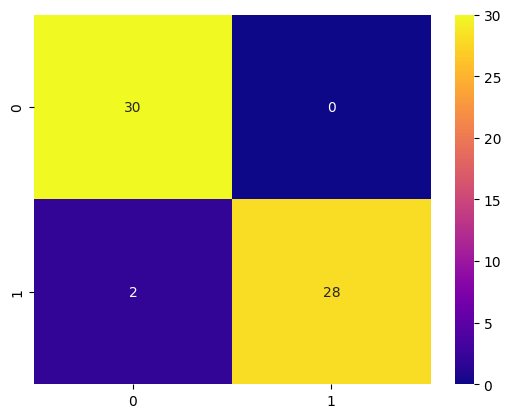

In [ ]:
import seaborn as sns
sns.heatmap(cm,cmap = "plasma" , annot=True)

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
class_names = ["Covid-19","Normal"]

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap="plasma"):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

Confusion matrix, without normalization
[[30  0]
 [ 2 28]]


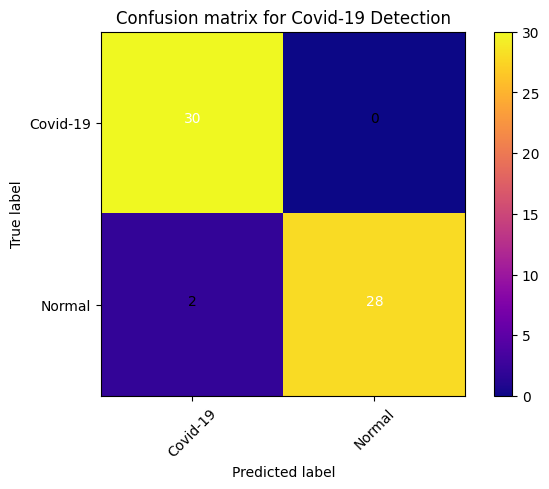

In [ ]:
plt.figure()
plot_confusion_matrix(cm, classes=class_names,
                      title='Confusion matrix for Covid-19 Detection',cmap="plasma")